# DME v2: drift estimation example

Fiducial-free drift correction for localization microscopy ([github.com/qnano/drift-estimation](https://github.com/qnano/drift-estimation)).
This notebook runs DME v2 on a simulated 3D dataset with known drift, and on the DNA-PAINT nanoruler dataset in `example_data/`.

On Colab, select a GPU runtime first (Runtime > Change runtime type > T4 GPU). It also runs on the CPU, but slower.

In [1]:
import os, sys
if 'google.colab' in sys.modules:
    !pip install -q git+https://github.com/qnano/drift-estimation.git h5py

import numpy as np
import matplotlib.pyplot as plt
import torch
from dme import dme_estimate, precision
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none, running on the CPU')

GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Simulated 3D data

Binding sites that blink on and off, shifted by a random-walk drift. Units: pixels for x and y, microns for z.

In [2]:
def smlm_simulation(drift_trace, fov_width, loc_error, n_sites, n_frames, on_prob=0.1, seed=0):
    rng = np.random.default_rng(seed)
    sites = rng.uniform([0, 0, -1], [fov_width, fov_width, 1], size=(n_sites, 3))
    frame, site = np.nonzero(rng.random((n_frames, n_sites)) < on_prob)
    locs = sites[site] + drift_trace[frame] + rng.normal(0, loc_error, size=(len(frame), 3))
    return locs.astype(np.float32), frame.astype(np.int32)

n_frames = 4000
loc_error = np.array([0.1, 0.1, 0.03])   # px, px, um
rng = np.random.default_rng(1)
drift_true = np.cumsum(rng.normal([0.001, 0, 0], 0.02, size=(n_frames, 3)), 0)
drift_true -= drift_true.mean(0)

localizations, framenum = smlm_simulation(drift_true, fov_width=200, loc_error=loc_error, n_sites=400, n_frames=n_frames)
crlb = np.tile(loc_error, (len(localizations), 1)).astype(np.float32)
print(f'{len(localizations)} localizations')

160157 localizations


DME v2 needs only the localizations, their frame numbers and their precision (CRLB). It chooses the temporal
resolution itself. For comparison, `method='v1'` runs the algorithm of the 2021 paper, with one spline knot per 20 frames.

DME v2: start = fixed spline at 50 frames/bin, learned prior with 6-frame segments
DME v2: start = fixed spline at 50 frames/bin, learned prior with 6-frame segments
dme_estimate (method=v2, device=cuda): 121.6s
RCC (10 bins) 0.05s
DME[full] N=160157 fpb=20 knots=200 evals=135 score=3.89862 time=2.89s
dme_estimate (method=v1, device=cuda): 2.9s
DME v2: RMS error vs. true drift = [0.01939239 0.01981404 0.01822649] (px, px, um)
DME v1: RMS error vs. true drift = [0.02800027 0.02837188 0.02836319] (px, px, um)
split-half precision estimate (v2): [0.00947821 0.00820453 0.00339831]


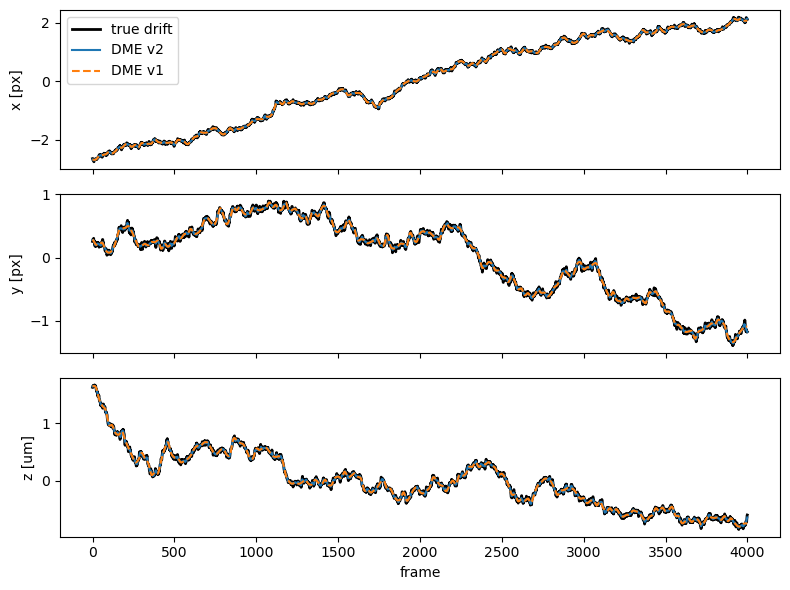

In [3]:
drift, (set1, set2) = dme_estimate(localizations, framenum, crlb)
drift_v1 = dme_estimate(localizations, framenum, crlb, framesperbin=20, method='v1', estimatePrecision=False)

for name, d in [('v2', drift), ('v1', drift_v1)]:
    print(f'DME {name}: RMS error vs. true drift = {np.sqrt(np.mean((d - d.mean(0) - drift_true) ** 2, 0))} (px, px, um)')
print(f'split-half precision estimate (v2): {precision(set1, set2)}')

fig, ax = plt.subplots(3, figsize=(8, 6), sharex=True)
for i in range(3):
    ax[i].plot(drift_true[:, i], 'k', lw=2, label='true drift')
    ax[i].plot(drift[:, i], label='DME v2')
    ax[i].plot(drift_v1[:, i], '--', label='DME v1')
    ax[i].set_ylabel(['x [px]', 'y [px]', 'z [um]'][i])
ax[0].legend()
ax[-1].set_xlabel('frame')
plt.tight_layout()

## 2. Real data: DNA-PAINT nanoruler (Picasso HDF5)

GATTAquant 80 nm nanoruler, 108.3 nm pixels. Localizations are read from a Picasso `.hdf5` file; `lpx` and `lpy` are
the localization precisions.

637794 localizations, 5000 frames
DME v2: start = fixed spline at 15 frames/bin, learned prior with 12-frame segments
dme_estimate (method=v2, device=cuda): 65.4s


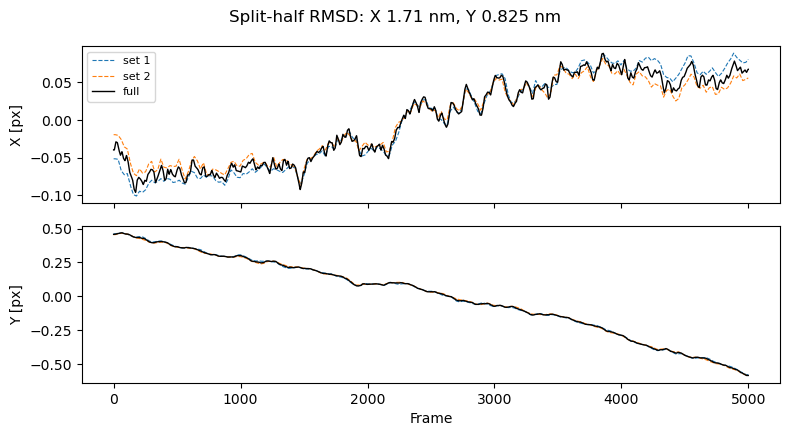

In [4]:
import h5py, urllib.request

fn = 'example_data/gattaquant 80nm RY.hdf5'
if not os.path.exists(fn):
    os.makedirs('example_data', exist_ok=True)
    urllib.request.urlretrieve('https://github.com/qnano/drift-estimation/raw/master/example_data/gattaquant%2080nm%20RY.hdf5', fn)
with h5py.File(fn, 'r') as f:
    locs = f['locs'][:]
pos = np.stack([locs['x'], locs['y']], 1)
crlb = np.stack([locs['lpx'], locs['lpy']], 1)
print(f"{len(locs)} localizations, {locs['frame'].max() + 1} frames")

drift, (set1, set2) = dme_estimate(pos, locs['frame'], crlb, pixelsize=108.3, display=True)
corrected = pos - drift[locs['frame']]

A single nanoruler (three binding sites, 80 nm apart) before and after drift correction. Use
`dme_example_picasso_hdf5.py` to write the corrected localizations back to a Picasso file.

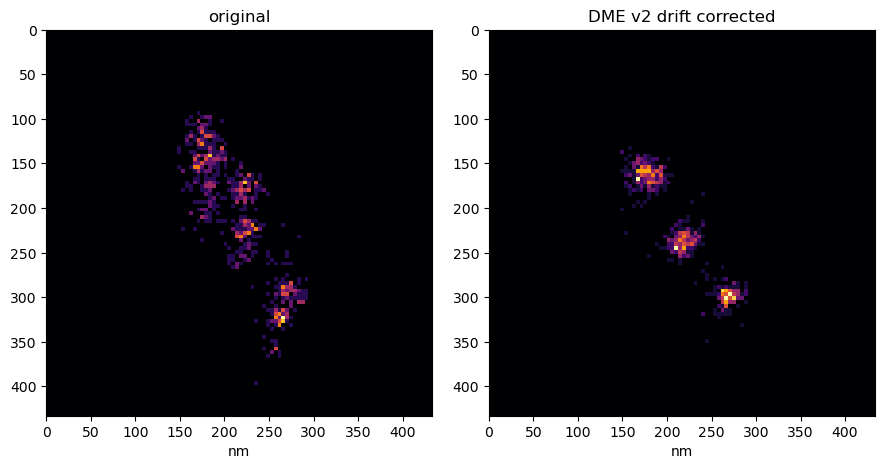

In [5]:
def render(p, ax, title, center=(20.6, 174.0), size=4, zoom=25):
    (cx, cy), nm = center, size * 108.3
    img, _, _ = np.histogram2d(p[:, 1], p[:, 0], bins=size * zoom, range=[[cy - size / 2, cy + size / 2], [cx - size / 2, cx + size / 2]])
    ax.imshow(img, cmap='inferno', extent=[0, nm, nm, 0])
    ax.set_title(title)
    ax.set_xlabel('nm')

fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
render(pos, ax[0], 'original')
render(corrected, ax[1], 'DME v2 drift corrected')
plt.tight_layout()